# Etapa 4: Rede neural para análise de sentimentos

**Tarefa:** a mesma da etapa 2, classificar avaliações de produtos em **positivo, neutro ou negativo**. Agora o classificador é uma rede neural em PyTorch.

**Por que esta tarefa?** No app, a classificação de sentimentos é o passo que transforma as menções encontradas pelo NER (etapa 3) em informação útil para a marca. Ela também se encaixa bem em uma arquitetura neural, porque o texto é uma sequência e a ordem das palavras importa ("bom" × "não é bom"). E já temos um baseline forte para comparar: **TF-IDF + Regressão Logística** (etapa 2), com acurácia de **0,951** e F1 macro de **0,883** no teste.

A rede é o **degrau do meio** de uma escada de modelos:

| Degrau | Modelo | O que traz | Etapa |
|---|---|---|---|
| 1 | TF-IDF + Regressão Logística | contagem de palavras e pares de palavras, sem ordem | 2 |
| **2** | **Rede neural (BiLSTM / BiGRU / CNN) + word embeddings** | **lê a sequência de palavras; pode usar vetores pré-treinados** | **4** |
| 3 | BERTimbau ajustado (*fine-tuning*) | Transformer pré-treinado em muito texto em português | 5 |

**Perguntas desta etapa:**
- **(a) Quanto vale ler a ordem das palavras?** Rede com embeddings aprendidos do zero × TF-IDF.
- **(b) Quanto vale o conhecimento prévio?** A mesma rede com embeddings pré-treinados (NILC GloVe e FastText) × embeddings do zero.

**Roteiro:**
0. Configuração (CPU/GPU)
1. Dados: mesma preparação e mesmo teste da etapa 2
2. Baseline TF-IDF + RL (reproduzido, para medir tempo e usar nas comparações)
3. Tokenização, tamanho máximo e vocabulário
4. Arquiteturas
5. Protocolo de treino
6. **Fase 1:** escolher a arquitetura (BiLSTM × BiGRU × CNN, embeddings do zero)
7. **Fase 2:** embeddings pré-treinados (NILC GloVe × FastText; congelado × ajustado)
8. Tabela final, curvas e matriz de confusão
9. Frases no estilo YouTube e erros conhecidos do TF-IDF
10. Avaliações mistas e análise de erros
11. Pontos fortes, limitações e conclusão

## 0. Configuração

O notebook roda em **CPU ou GPU**. A célula abaixo escolhe a GPU se o PyTorch instalado tiver suporte a CUDA; caso contrário, usa a CPU. O conjunto de dados é pequeno (cerca de 6.400 textos curtos), então **a CPU dá conta**: nesta execução, cada época levou alguns segundos.

<details>
<summary><b>Como instalar o PyTorch com CUDA (opcional)</b></summary>

1. Verifique a versão de CUDA suportada pelo driver: `nvidia-smi` (canto superior direito).
2. Instale o build correspondente a partir do índice oficial (exemplo para CUDA 13.0):
   ```bash
   pip uninstall -y torch
   pip install torch --index-url https://download.pytorch.org/whl/cu130
   ```
   Para CUDA 12.8 troque `cu130` por `cu128`. **GPUs da série RTX 50 (Blackwell)** precisam de CUDA 12.8 ou mais novo.
   O download tem cerca de 2 GB. Veja https://pytorch.org/get-started/locally/.
3. Confira: `python -c "import torch; print(torch.cuda.is_available())"` deve mostrar `True`.

</details>

Os números deste notebook foram obtidos na **CPU** (torch 2.15.0+cpu). Na GPU, os tempos mudam, e os resultados podem variar um pouco por causa do não determinismo das operações em CUDA.

In [1]:
import sys, time, random, copy, inspect, unicodedata
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

sys.path.insert(0, str(Path("..").resolve()))          # para importar src/ (rodar a partir de notebooks/)
from src.dados import (carregar_repro, dividir_treino_teste, dividir_validacao,
                       tokenizar, limpar, CLASSES, SEED)
from src.redes import (Vocabulario, codificar_textos, BiRNN, CNNTexto, criar_modelo,
                       salvar_modelo, ClassificadorSentimento)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# DEVICE = torch.device("cpu")  # descomente para forçar CPU

PASTA_EMB = Path("../data/embeddings")
PASTA_REPORTS = Path("../reports"); PASTA_REPORTS.mkdir(exist_ok=True)
PASTA_MODELS = Path("../models"); PASTA_MODELS.mkdir(exist_ok=True)

pd.set_option("display.max_colwidth", 160)
print("torch", torch.__version__, "| device:", DEVICE,
      "| threads CPU:", torch.get_num_threads())
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(0))

torch 2.15.0+cpu | device: cpu | threads CPU: 16


## 1. Dados: a mesma preparação da etapa 2

Para a comparação com o TF-IDF ser justa, **os textos e o conjunto de teste precisam ser exatamente os mesmos**. Por isso a preparação da etapa 2 foi movida para um módulo reutilizável, [`src/dados.py`](../src/dados.py), com os mesmos passos:
`ast.literal_eval` em `polarity` → 3 classes, com os mistos fora → `limpar(título + ". " + texto)` → `train_test_split(test_size=0.2, stratify=..., random_state=42)`.

**Validação:** do treino, separamos 15% (estratificado) para o *early stopping* e para escolher modelos. **O teste fica intocado** e só é usado para reportar resultados.

In [2]:
dados, mistos = carregar_repro()
X_train, X_test, y_train, y_test = dividir_treino_teste(dados)
X_tr, X_val, y_tr, y_val = dividir_validacao(X_train, y_train, val_size=0.15)

# Confere que é o mesmo split da etapa 2
assert (len(X_train), len(X_test)) == (6388, 1597)
assert y_test.value_counts().to_dict() == {"positivo": 825, "negativo": 690, "neutro": 82}

pd.DataFrame({
    "treino (rede)": y_tr.value_counts(), "validação": y_val.value_counts(),
    "teste": y_test.value_counts(), "mistos (fora)": pd.Series({"misto": len(mistos)}),
}).reindex(CLASSES + ["misto"]).fillna(0).astype(int)

,treino (rede),validação,teste,mistos (fora)
positivo,2806,496,825,0
neutro,278,49,82,0
negativo,2345,414,690,0
misto,0,0,0,2018


## 2. Baseline: TF-IDF + Regressão Logística

Treinamos de novo o mesmo pipeline da etapa 2 (mesmos hiperparâmetros e mesmo treino de 6.388 avaliações). Os números devem ser idênticos aos de lá (acurácia 0,951 e F1 macro 0,883). Treinar de novo aqui permite medir o **tempo de treino e de inferência** na mesma máquina e comparar as previsões frase a frase com a rede.

In [3]:
def medir_latencia(prever_um, textos, n=300):
    # Tempo médio (ms) para classificar UM comentário por vez, como no app
    amostra = list(textos[:n])
    prever_um(amostra[0])                                   # aquecimento
    t = time.perf_counter()
    for txt in amostra:
        prever_um(txt)
    return (time.perf_counter() - t) / len(amostra) * 1000

t0 = time.perf_counter()
tfidf_rl = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9, strip_accents="unicode", sublinear_tf=True)),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", C=2.0, random_state=SEED)),
]).fit(X_train, y_train)
tempo_treino_tfidf = time.perf_counter() - t0

pred_tfidf = tfidf_rl.predict(X_test)
lat_tfidf = medir_latencia(lambda t: tfidf_rl.predict([t]), list(X_test))
n_param_tfidf = tfidf_rl.named_steps["clf"].coef_.size + tfidf_rl.named_steps["clf"].intercept_.size

print(f"Acurácia {accuracy_score(y_test, pred_tfidf):.3f} | F1 macro {f1_score(y_test, pred_tfidf, average='macro'):.3f}")
print(f"Treino: {tempo_treino_tfidf:.1f} s | inferência: {lat_tfidf:.2f} ms/comentário | parâmetros: {n_param_tfidf:,}")
print(classification_report(y_test, pred_tfidf, digits=3))

Acurácia 0.951 | F1 macro 0.883
Treino: 0.4 s | inferência: 0.44 ms/comentário | parâmetros: 53,310
              precision    recall  f1-score   support

    negativo      0.938     0.959     0.948       690
      neutro      0.685     0.768     0.724        82
    positivo      0.992     0.961     0.977       825

    accuracy                          0.951      1597
   macro avg      0.872     0.896     0.883      1597
weighted avg      0.953     0.951     0.951      1597



## 3. Tokenização, tamanho máximo e vocabulário

**Tokenização** (`src.dados.tokenizar`): o texto já vem em minúsculas da função `limpar`. Separamos palavras (com acentos e hífen interno, como "guarda-roupa") e símbolos isolados (pontuação e emojis viram tokens próprios: "!", "?", "🙄").
- **Acentos mantidos:** os embeddings do NILC e do FastText foram treinados com acentos. "não" e "nao" são vetores diferentes, e o texto correto (com acento) é o mais frequente. A cobertura de cada normalização é medida na Fase 2.
- **Pontuação e emojis mantidos:** "!!!", "?" (perguntas costumam ser neutras no RePro) e emojis carregam sentimento.
- **Sem remover stopwords**, pelo mesmo motivo da etapa 2: "não" e "nem" mudam o sentido.

**Tamanho máximo:** usamos o percentil 95 do número de tokens no treino, arredondado para cima até a dezena. Textos maiores são truncados no fim, o que preserva o título, que vem no início e costuma resumir a opinião. Textos menores recebem `<pad>`. As RNNs usam o tamanho real de cada texto (`pack_padded_sequence`), então o padding não interfere nelas.

**Vocabulário:** palavras com frequência ≥ 2 no treino da rede, mais `<pad>` (índice 0) e `<unk>` (índice 1, para palavras desconhecidas). Palavras que aparecem uma única vez quase não podem ser aprendidas do zero e só aumentam o ruído.

Percentis de tamanho (tokens) 50/75/90/95/99: [ 23.  36.  56.  75. 127.]
MAX_LEN = 80 → 4.1% dos textos de treino são truncados


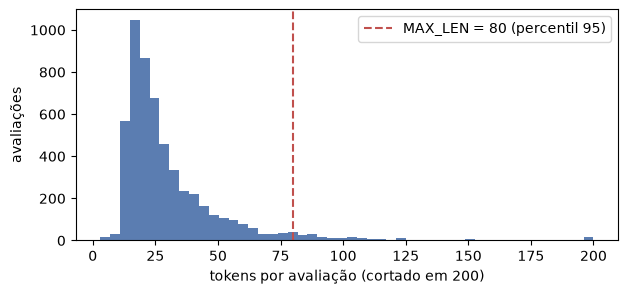

Vocabulário (min_freq=2): 4,726 tokens | <unk> na validação: 4.5% | no teste: 5.2% dos tokens


In [4]:
tok_tr = [tokenizar(t) for t in X_tr]
tamanhos = np.array([len(t) for t in tok_tr])
pct = np.percentile(tamanhos, [50, 75, 90, 95, 99])
MAX_LEN = int(np.ceil(pct[3] / 10) * 10)
print("Percentis de tamanho (tokens) 50/75/90/95/99:", pct.round(0))
print(f"MAX_LEN = {MAX_LEN} → {np.mean(tamanhos > MAX_LEN):.1%} dos textos de treino são truncados")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(np.minimum(tamanhos, 200), bins=50, color="#5B7DB1")
ax.axvline(MAX_LEN, color="#C0504D", ls="--", label=f"MAX_LEN = {MAX_LEN} (percentil 95)")
ax.set_xlabel("tokens por avaliação (cortado em 200)"); ax.set_ylabel("avaliações"); ax.legend()
plt.show()

MIN_FREQ = 2
vocab_zero = Vocabulario.construir(tok_tr, min_freq=MIN_FREQ)
def taxa_unk(textos, vocab):
    toks = [t for txt in textos for t in tokenizar(txt)]
    return np.mean([t not in vocab.stoi for t in toks])
print(f"Vocabulário (min_freq={MIN_FREQ}): {len(vocab_zero):,} tokens | "
      f"<unk> na validação: {taxa_unk(X_val, vocab_zero):.1%} | no teste: {taxa_unk(X_test, vocab_zero):.1%} dos tokens")

## 4. Arquiteturas

As três arquiteturas estão em [`src/redes.py`](../src/redes.py), para o app poder carregar o modelo sem o notebook. Todas têm a mesma "moldura": **embedding de 300 dimensões → codificador → vetor do texto → dropout → camada linear com 3 saídas**. O que muda é o codificador:

| Arquitetura | Codificador | Como vira um vetor do texto |
|---|---|---|
| **BiLSTM** | LSTM bidirecional, 128 unidades por direção | *max pooling* no tempo sobre as saídas (256 dim.) |
| **BiGRU** | GRU bidirecional, 128 por direção (portões mais simples que a LSTM) | *max pooling* no tempo (256 dim.) |
| **CNN 1D** (Kim, 2014) | 100 filtros para cada janela de 2, 3, 4 e 5 palavras | *max pooling* de cada filtro (400 dim.) |

- **BiLSTM e BiGRU** leem a frase nos dois sentidos, então cada palavra é vista com o contexto à esquerda e à direita. Em tese, conseguem capturar negações e ressalvas de longo alcance ("não tem igual", "bom, porém...").
- **CNN** detecta **padrões locais** de 2 a 5 palavras ("não recomendo", "não tem igual", "top demais"), em qualquer posição. É mais rápida e paralelizável.
- O tamanho foi escolhido para os codificadores terem um **número de parâmetros parecido** (de 330 mil a 440 mil, sem contar o embedding).
- **Dropout:** 0,25 sobre os embeddings e 0,5 antes da camada final, porque o conjunto de treino é pequeno.

In [5]:
print(inspect.getsource(BiRNN))
print(inspect.getsource(CNNTexto))

class BiRNN(nn.Module):
    """Embedding -> LSTM ou GRU bidirecional -> max pooling no tempo -> camada linear."""

    def __init__(self, n_vocab, n_classes, emb_dim=300, hidden=128, tipo="lstm",
                 dropout_emb=0.25, dropout=0.5):
        super().__init__()
        self.embedding = nn.Embedding(n_vocab, emb_dim, padding_idx=0)
        rnn = nn.LSTM if tipo == "lstm" else nn.GRU
        self.rnn = rnn(emb_dim, hidden, batch_first=True, bidirectional=True)
        self.drop_emb = nn.Dropout(dropout_emb)
        self.drop = nn.Dropout(dropout)
        self.saida = nn.Linear(2 * hidden, n_classes)

    def forward(self, x, tamanhos):
        e = self.drop_emb(self.embedding(x))
        # "pack" faz a direção de trás para frente começar na última palavra real, não no padding
        pacote = pack_padded_sequence(e, tamanhos.cpu(), batch_first=True, enforce_sorted=False)
        h, _ = self.rnn(pacote)
        h, _ = pad_packed_sequence(h, batch_first=True, total_length=x.size(


class CNNTexto(nn.Module):
    """CNN 1D estilo Kim (2014): filtros de 2, 3, 4 e 5 palavras + max pooling no tempo."""

    def __init__(self, n_vocab, n_classes, emb_dim=300, n_filtros=100, janelas=(2, 3, 4, 5),
                 dropout_emb=0.25, dropout=0.5):
        super().__init__()
        self.embedding = nn.Embedding(n_vocab, emb_dim, padding_idx=0)
        self.convs = nn.ModuleList(nn.Conv1d(emb_dim, n_filtros, k) for k in janelas)
        self.drop_emb = nn.Dropout(dropout_emb)
        self.drop = nn.Dropout(dropout)
        self.saida = nn.Linear(n_filtros * len(janelas), n_classes)

    def forward(self, x, tamanhos=None):
        e = self.drop_emb(self.embedding(x)).transpose(1, 2)          # [B, emb, T]
        h = torch.cat([torch.relu(c(e)).max(dim=2).values for c in self.convs], dim=1)
        return self.saida(self.drop(h))



## 5. Protocolo de treino

| Item | Escolha | Por quê |
|---|---|---|
| Perda | Entropia cruzada **com pesos por classe** (`n / (3 · n_classe)`) | O neutro é raro (5%); sem peso, a rede o ignora (equivale ao `class_weight="balanced"` da etapa 2) |
| Otimizador | Adam, taxa 1e-3, lote 64, corte de gradiente em 5 | Configuração padrão e estável para RNN e CNN |
| Épocas | Até 20, com **early stopping** pelo **F1 macro da validação** (paciência 4) | O F1 macro dá o mesmo peso ao neutro; guardamos os pesos da melhor época |
| Sementes | 3 (42, 43, 44) para cada configuração; reportamos **média ± desvio padrão** | Com poucos neutros, a variação entre sementes é grande; um único número engana |
| Escolha do melhor | Pela **validação**, nunca pelo teste | O teste só serve para reportar |

A semente muda a inicialização dos pesos, a ordem dos lotes e o dropout. A divisão treino/validação é sempre a mesma.

In [6]:
cls2id = {c: i for i, c in enumerate(CLASSES)}
ytr_ids = torch.tensor([cls2id[c] for c in y_tr])
yval_ids = np.array([cls2id[c] for c in y_val])
ytest_ids = np.array([cls2id[c] for c in y_test])

contagem = np.bincount(ytr_ids.numpy(), minlength=len(CLASSES))
PESOS_CLASSE = torch.tensor(len(ytr_ids) / (len(CLASSES) * contagem), dtype=torch.float32)
print("Pesos por classe:", dict(zip(CLASSES, PESOS_CLASSE.numpy().round(2))))

SEEDS = [42, 43, 44]
HP = dict(lr=1e-3, batch=64, max_epocas=20, paciencia=4, clip=5.0)

def fixar_semente(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)

@torch.no_grad()
def prever_ids(modelo, X, L, batch=512):
    modelo.eval()
    saidas = [modelo(X[i:i+batch].to(DEVICE), L[i:i+batch]).cpu() for i in range(0, len(X), batch)]
    return torch.cat(saidas)                          # logits [N, 3]

def contar_parametros(modelo):
    total = sum(p.numel() for p in modelo.parameters())
    treinaveis = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
    return total, treinaveis

def treinar(arquitetura, vocab, seed, pesos_emb=None, congelar=False):
    # Treina uma configuração com uma semente. Devolve métricas, histórico e os pesos da melhor época.
    fixar_semente(seed)
    modelo = criar_modelo(arquitetura, len(vocab), len(CLASSES)).to(DEVICE)
    if pesos_emb is not None:
        modelo.embedding.weight.data.copy_(torch.as_tensor(pesos_emb))
        modelo.embedding.weight.requires_grad = not congelar

    Xtr, Ltr = codificar_textos(X_tr, vocab, MAX_LEN)
    Xv, Lv = codificar_textos(X_val, vocab, MAX_LEN)
    perda_fn = nn.CrossEntropyLoss(weight=PESOS_CLASSE.to(DEVICE))
    opt = torch.optim.Adam([p for p in modelo.parameters() if p.requires_grad], lr=HP["lr"])
    gerador = torch.Generator().manual_seed(seed)

    hist, melhor_f1, melhor_estado, melhor_epoca, sem_melhora = [], -1, None, 0, 0
    t0 = time.perf_counter()
    for epoca in range(1, HP["max_epocas"] + 1):
        modelo.train(); soma, n = 0.0, 0
        for idx in torch.randperm(len(Xtr), generator=gerador).split(HP["batch"]):
            xb, lb, yb = Xtr[idx].to(DEVICE), Ltr[idx], ytr_ids[idx].to(DEVICE)
            opt.zero_grad()
            perda = perda_fn(modelo(xb, lb), yb)
            perda.backward()
            nn.utils.clip_grad_norm_(modelo.parameters(), HP["clip"])
            opt.step()
            soma += perda.item() * len(idx); n += len(idx)
        logits_v = prever_ids(modelo, Xv, Lv)
        perda_v = perda_fn(logits_v.to(DEVICE), torch.as_tensor(yval_ids, device=DEVICE)).item()
        f1_v = f1_score(yval_ids, logits_v.argmax(1).numpy(), average="macro")
        hist.append({"epoca": epoca, "perda_treino": soma / n, "perda_val": perda_v, "f1_val": f1_v})
        if f1_v > melhor_f1:
            melhor_f1, melhor_epoca, sem_melhora = f1_v, epoca, 0
            melhor_estado = copy.deepcopy(modelo.state_dict())
        else:
            sem_melhora += 1
            if sem_melhora >= HP["paciencia"]:
                break
    tempo_treino = time.perf_counter() - t0

    modelo.load_state_dict(melhor_estado)
    Xte, Lte = codificar_textos(X_test, vocab, MAX_LEN)
    pred = prever_ids(modelo, Xte, Lte).argmax(1).numpy()

    def prever_um(txt):
        x, l = codificar_textos([txt], vocab, MAX_LEN)
        return prever_ids(modelo, x, l).argmax(1)
    latencia = medir_latencia(prever_um, list(X_test))

    total, treinaveis = contar_parametros(modelo)
    f1s = f1_score(ytest_ids, pred, average=None, labels=range(len(CLASSES)))
    return {
        "seed": seed, "f1_val": melhor_f1, "melhor_epoca": melhor_epoca, "epocas": len(hist),
        "acuracia": accuracy_score(ytest_ids, pred), "f1_macro": f1_score(ytest_ids, pred, average="macro"),
        **{f"f1_{c}": f for c, f in zip(CLASSES, f1s)},
        "param_total": total, "param_treinaveis": treinaveis,
        "tempo_treino_s": tempo_treino, "inferencia_ms": latencia,
        "historico": pd.DataFrame(hist), "pred_teste": pred, "estado": melhor_estado,
    }

RESULTADOS = {}      # nome da configuração -> lista de resultados (um por semente)
MELHORES = {}        # nome -> resultado da melhor semente (pela validação), com os pesos

def rodar(nome, arquitetura, vocab, pesos_emb=None, congelar=False):
    runs = []
    for s in SEEDS:
        r = treinar(arquitetura, vocab, s, pesos_emb, congelar)
        print(f"  {nome:28s} seed {s}: F1 val {r['f1_val']:.3f} | F1 macro teste {r['f1_macro']:.3f} | "
              f"F1 neutro {r['f1_neutro']:.3f} | {r['epocas']} épocas, {r['tempo_treino_s']:.0f} s")
        runs.append(r)
    melhor = max(runs, key=lambda r: r["f1_val"])
    MELHORES[nome] = {**melhor, "arquitetura": arquitetura, "vocab": vocab}
    for r in runs:                          # libera memória: só guarda os pesos da melhor semente
        r.pop("estado")
    RESULTADOS[nome] = runs

METRICAS = ["f1_val", "acuracia", "f1_macro", "f1_positivo", "f1_neutro", "f1_negativo",
            "tempo_treino_s", "inferencia_ms", "epocas"]
def resumo(nomes=None):
    linhas = []
    for nome in (nomes or RESULTADOS):
        df = pd.DataFrame([{k: r[k] for k in METRICAS + ["param_total", "param_treinaveis"]} for r in RESULTADOS[nome]])
        linha = {"configuração": nome}
        for k in METRICAS:
            linha[k], linha[k + "_dp"] = df[k].mean(), df[k].std()
        linha["param_total"], linha["param_treinaveis"] = df["param_total"].iloc[0], df["param_treinaveis"].iloc[0]
        linhas.append(linha)
    return pd.DataFrame(linhas).set_index("configuração")

def fmt(tab, cols=("f1_val", "acuracia", "f1_macro", "f1_neutro")):
    out = pd.DataFrame(index=tab.index)
    for c in cols:
        out[c] = [f"{m:.3f} ± {d:.3f}" for m, d in zip(tab[c], tab[c + "_dp"])]
    return out

Pesos por classe: {'positivo': np.float32(0.64), 'neutro': np.float32(6.51), 'negativo': np.float32(0.77)}


## 6. Fase 1: escolher a arquitetura (embeddings aprendidos do zero)

As três arquiteturas usam o mesmo vocabulário, o mesmo `MAX_LEN` e os mesmos hiperparâmetros. Os embeddings começam aleatórios e são aprendidos só com as ~5.400 avaliações de treino. **A vencedora é escolhida pela média do F1 macro na validação.**

In [7]:
FASE1 = {"BiLSTM (do zero)": "bilstm", "BiGRU (do zero)": "bigru", "CNN (do zero)": "cnn"}
for nome, arq in FASE1.items():
    print(nome)
    rodar(nome, arq, vocab_zero)

BiLSTM (do zero)


  BiLSTM (do zero)             seed 42: F1 val 0.906 | F1 macro teste 0.874 | F1 neutro 0.710 | 13 épocas, 155 s


  BiLSTM (do zero)             seed 43: F1 val 0.900 | F1 macro teste 0.875 | F1 neutro 0.720 | 11 épocas, 148 s


  BiLSTM (do zero)             seed 44: F1 val 0.913 | F1 macro teste 0.862 | F1 neutro 0.667 | 14 épocas, 169 s
BiGRU (do zero)


  BiGRU (do zero)              seed 42: F1 val 0.910 | F1 macro teste 0.871 | F1 neutro 0.698 | 15 épocas, 154 s


  BiGRU (do zero)              seed 43: F1 val 0.917 | F1 macro teste 0.871 | F1 neutro 0.705 | 14 épocas, 143 s


  BiGRU (do zero)              seed 44: F1 val 0.893 | F1 macro teste 0.863 | F1 neutro 0.684 | 9 épocas, 109 s
CNN (do zero)


  CNN (do zero)                seed 42: F1 val 0.889 | F1 macro teste 0.886 | F1 neutro 0.748 | 12 épocas, 72 s


  CNN (do zero)                seed 43: F1 val 0.883 | F1 macro teste 0.862 | F1 neutro 0.681 | 11 épocas, 65 s


  CNN (do zero)                seed 44: F1 val 0.885 | F1 macro teste 0.851 | F1 neutro 0.649 | 11 épocas, 74 s


In [8]:
tab1 = resumo(list(FASE1))
VENCEDORA_NOME = tab1["f1_val"].idxmax()
VENCEDORA = FASE1[VENCEDORA_NOME]
print("Vencedora da Fase 1 (maior F1 macro médio na validação):", VENCEDORA_NOME)
fmt(tab1).join(tab1[["param_treinaveis", "tempo_treino_s", "epocas"]].round(1))

Vencedora da Fase 1 (maior F1 macro médio na validação): BiGRU (do zero)


,f1_val,acuracia,f1_macro,f1_neutro,param_treinaveis,tempo_treino_s,epocas
configuração,,,,,,,
BiLSTM (do zero),0.907 ± 0.006,0.943 ± 0.002,0.870 ± 0.007,0.699 ± 0.028,1858891,157.1,12.7
BiGRU (do zero),0.907 ± 0.012,0.942 ± 0.004,0.868 ± 0.005,0.696 ± 0.010,1748811,135.7,12.7
CNN (do zero),0.885 ± 0.003,0.941 ± 0.004,0.866 ± 0.018,0.693 ± 0.051,1839403,70.4,11.3


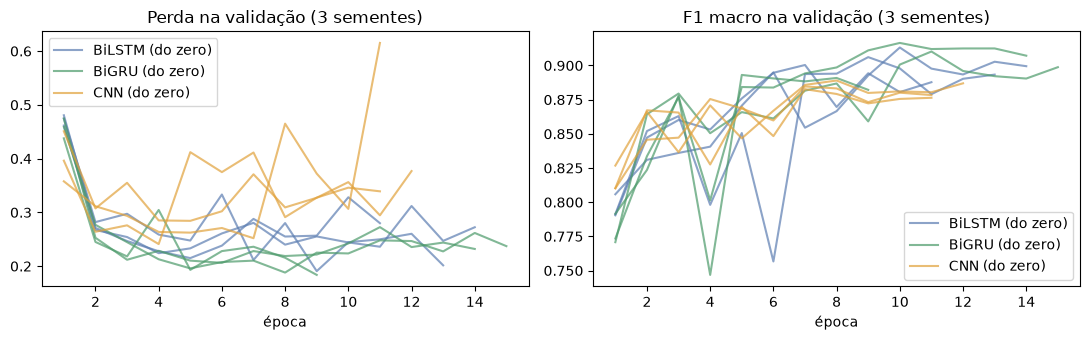

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
cores = {"BiLSTM (do zero)": "#5B7DB1", "BiGRU (do zero)": "#4C9A6A", "CNN (do zero)": "#E1A13A"}
for nome in FASE1:
    for i, r in enumerate(RESULTADOS[nome]):
        h = r["historico"]; rot = nome if i == 0 else None
        axs[0].plot(h["epoca"], h["perda_val"], color=cores[nome], alpha=.7, label=rot)
        axs[1].plot(h["epoca"], h["f1_val"], color=cores[nome], alpha=.7, label=rot)
axs[0].set_title("Perda na validação (3 sementes)"); axs[1].set_title("F1 macro na validação (3 sementes)")
for a in axs: a.set_xlabel("época"); a.legend()
plt.tight_layout(); plt.show()

## 7. Fase 2: embeddings pré-treinados na arquitetura vencedora

Embeddings aprendidos do zero só "conhecem" as ~5 mil palavras que aparecem pelo menos duas vezes no treino. Embeddings **pré-treinados** trazem o significado aprendido em **bilhões de palavras**: "péssimo" fica perto de "horrível" mesmo que uma das duas nunca apareça no RePro. Testamos dois:

| | **(B) NILC GloVe 300d** | **(C) FastText cc.pt.300 (Facebook)** |
|---|---|---|
| Fonte | NILC-USP ([repositório](http://nilc.icmc.usp.br/embeddings); cópia oficial em [huggingface.co/nilc-nlp/glove-300d](https://huggingface.co/nilc-nlp/glove-300d)) | [fasttext.cc](https://fasttext.cc/docs/en/crawl-vectors.html) (Grave et al., 2018) |
| Corpus | 1,39 bilhão de tokens de 17 corpora em PT-BR e PT-PT (notícias, Wikipédia, literatura, textos didáticos...) | Common Crawl + Wikipédia (texto da web, mais informal) |
| Algoritmo | GloVe (coocorrência global) | FastText CBOW com subpalavras |
| Tamanho bruto | 1,12 GB | 1,27 GB (`.vec.gz`, 2 milhões de palavras) |

**Por que esses dois:** GloVe do NILC é a referência acadêmica para português, e o FastText do Facebook vem de **texto da web**, mais perto do registro do YouTube (gírias, abreviações, emojis). Os dois têm 300 dimensões, o mesmo tamanho da Fase 1, então a arquitetura não muda.

**Downloads:** feitos por [`utils/baixar_embeddings.py`](../utils/baixar_embeddings.py). Para economizar disco e memória, o script guarda só um **recorte**: todas as palavras que aparecem no RePro (com e sem acento) mais as **50.000 mais frequentes** de cada embedding. Os arquivos ficam em `data/embeddings/` (fora do git). O `.vec` tem só vetores de palavras inteiras; os vetores por subpalavra do FastText ficam no `.bin`, que tem 4,5 GB compactado, por isso não foram usados.

**Vocabulário da Fase 2:** vocabulário do treino (min_freq 2) **mais** as 50.000 palavras mais frequentes do embedding. Assim, uma palavra que nunca apareceu no treino, mas é comum em português ("top", "mano", "decepcionante"), ainda tem um vetor com significado. Isso é parte do que o conhecimento prévio oferece. A lista das 50 mil mais frequentes vem só do embedding e não usa o teste. Palavras do treino que não existem no embedding começam com um vetor aleatório (mesma escala dos vetores pré-treinados).

In [10]:
def sem_acento(p):
    return "".join(c for c in unicodedata.normalize("NFD", p) if unicodedata.category(c) != "Mn")

def carregar_emb(nome):
    z = np.load(PASTA_EMB / f"{nome}_filtrado.npz")
    palavras = [str(p) for p in z["palavras"]]
    return {"stoi": {p: i for i, p in enumerate(palavras)}, "vetores": z["vetores"],
            "top": [p for p, r in zip(palavras, z["rank"]) if r < 50_000]}

EMB = {"NILC GloVe": carregar_emb("glove_nilc"), "FastText FB": carregar_emb("fasttext_fb")}

# Cobertura do vocabulário do treino em duas normalizações:
# (1) minúsculas com acento (como o texto está) e (2) minúsculas sem acento.
from collections import Counter
cont_tr = Counter(t for toks in tok_tr for t in toks)
vocab_tr = [w for w in vocab_zero.itos[2:]]
linhas = []
for nome, e in EMB.items():
    for norm, f in [("minúsculas, com acento", lambda w: w), ("minúsculas, sem acento", sem_acento)]:
        tipos = np.mean([f(w) in e["stoi"] for w in vocab_tr])
        ocorr = sum(c for w, c in cont_tr.items() if f(w) in e["stoi"]) / sum(cont_tr.values())
        linhas.append({"embedding": nome, "normalização": norm,
                       "cobertura do vocabulário (tipos)": f"{tipos:.1%}",
                       "cobertura do texto (ocorrências)": f"{ocorr:.1%}"})
display(pd.DataFrame(linhas))

tokens_yt = ["top", "mano", "demais", "brabo", "kkkkk", "kkk", "tô", "passado", "🔥", "🙄", "👏", "😍", "👍", "zenfone", "intermediários"]
cob_yt = pd.DataFrame({nome: ["✅" if t in e["stoi"] else "—" for t in tokens_yt] for nome, e in EMB.items()}, index=tokens_yt)
cob_yt["vocab. do zero (treino)"] = ["✅" if t in vocab_zero.stoi else "—" for t in tokens_yt]
print("Tokens típicos do YouTube: têm vetor no recorte salvo (RePro + 50 mil mais frequentes)? Estão no vocabulário do zero?")
cob_yt.T

,embedding,normalização,cobertura do vocabulário (tipos),cobertura do texto (ocorrências)
0,NILC GloVe,"minúsculas, com acento",98.4%,99.3%
1,NILC GloVe,"minúsculas, sem acento",96.2%,98.8%
2,FastText FB,"minúsculas, com acento",99.7%,99.7%
3,FastText FB,"minúsculas, sem acento",99.6%,99.7%


Tokens típicos do YouTube: têm vetor no recorte salvo (RePro + 50 mil mais frequentes)? Estão no vocabulário do zero?


,top,mano,demais,brabo,kkkkk,kkk,tô,passado,🔥,🙄,👏,😍,👍,zenfone,intermediários
NILC GloVe,✅,✅,✅,—,✅,✅,✅,✅,—,—,—,—,—,✅,✅
FastText FB,✅,✅,✅,—,✅,✅,✅,✅,—,—,—,—,—,✅,✅
vocab. do zero (treino),✅,—,✅,—,✅,✅,✅,✅,—,—,—,—,—,✅,—


In [11]:
for nome, e in EMB.items():
    faltam = [w for w, c in cont_tr.most_common() if w not in e["stoi"]][:20]
    print(f"\n{nome}: tokens frequentes do treino SEM vetor →", faltam)


NILC GloVe: tokens frequentes do treino SEM vetor → ['"', 'à', 'maisnunca', 'entregademora', 'às', 'asdf', 'produtogostei', '…', 'colchao', 'decepçao', 'directlog', 'recomendadíssimo', '”', 'descosturou', 'muinto', 'reclamacao', 'fabricacao', 'ameiii', 'devolucao', '“']

FastText FB: tokens frequentes do treino SEM vetor → ['entregademora', 'produtogostei', 'directlog', 'verticoil', 'ciamob', 'i-menu', 'aparêlho', 'rebebi', 'priduto', 'mototico', 'tatufast', 'silencoso', 'momtar', 'climup', 'mdeira', 'jesus-o', 'acidua', 'aparélio', 'matório', 'liquefaziam']


**Escolha da normalização:** manter os acentos dá a **maior cobertura nos dois embeddings** (tabela acima). Tirar os acentos transforma "não" em "nao" e "é" em "e", que existem no embedding, mas como palavras raras ou diferentes. Por isso o texto fica como está: minúsculas com acento, para os dois. No FastText, que diferencia maiúsculas, o script guarda, para cada palavra em minúsculas, a grafia mais frequente.

### Congelar ou ajustar os embeddings?

- **Congelado:** os vetores pré-treinados não mudam. A rede aprende só o codificador (BiLSTM/CNN) e a camada final. **Vantagens:** menos parâmetros treináveis, menos risco de sobreajuste com só ~5 mil exemplos, e palavras que **não aparecem no treino** continuam coerentes com as que aparecem (o espaço não "entorta"). **Desvantagem:** os vetores não se adaptam à tarefa. Em GloVe/FastText, "bom" e "ruim" ficam **próximos**, porque aparecem nos mesmos contextos.
- **Ajustado (*fine-tuning*):** os vetores partem do pré-treino e são atualizados pelo gradiente. **Vantagem:** podem separar "bom" de "ruim". **Desvantagem:** só as palavras do treino se movem, então as que não aparecem no treino ficam "para trás", num espaço que não combina mais com o resto, e o risco de sobreajuste aumenta (com o vocabulário ampliado, são milhões de parâmetros a mais).

Como cada treino leva poucos minutos, **testamos os dois** para cada embedding: 4 configurações × 3 sementes.

In [12]:
def montar_vocab_e_matriz(e, seed=SEED):
    vocab = Vocabulario.construir(tok_tr, min_freq=MIN_FREQ, extras=e["top"])
    V = e["vetores"]; rng = np.random.default_rng(seed)
    M = rng.normal(0, V.std(), size=(len(vocab), V.shape[1])).astype(np.float32)
    M[0] = 0                                                      # <pad>
    achou = 0
    for i, w in enumerate(vocab.itos[2:], start=2):
        j = e["stoi"].get(w)
        if j is not None:
            M[i] = V[j]; achou += 1
    print(f"  vocabulário {len(vocab):,} palavras | {achou / (len(vocab) - 2):.1%} com vetor pré-treinado | "
          f"<unk> no teste: {taxa_unk(X_test, vocab):.1%} dos tokens (do zero: {taxa_unk(X_test, vocab_zero):.1%})")
    return vocab, M

FASE2 = {}
for nome_emb, e in EMB.items():
    print(nome_emb)
    vocab_e, M = montar_vocab_e_matriz(e)
    for congelar in (True, False):
        nome = f"{VENCEDORA_NOME.split(' ')[0]} + {nome_emb} ({'congelado' if congelar else 'ajustado'})"
        FASE2[nome] = nome_emb
        rodar(nome, VENCEDORA, vocab_e, pesos_emb=M, congelar=congelar)

NILC GloVe


  vocabulário 50,641 palavras | 99.9% com vetor pré-treinado | <unk> no teste: 2.0% dos tokens (do zero: 5.2%)


  BiGRU + NILC GloVe (congelado) seed 42: F1 val 0.932 | F1 macro teste 0.896 | F1 neutro 0.757 | 19 épocas, 307 s


  BiGRU + NILC GloVe (congelado) seed 43: F1 val 0.878 | F1 macro teste 0.847 | F1 neutro 0.650 | 6 épocas, 76 s


  BiGRU + NILC GloVe (congelado) seed 44: F1 val 0.928 | F1 macro teste 0.888 | F1 neutro 0.729 | 12 épocas, 144 s


  BiGRU + NILC GloVe (ajustado) seed 42: F1 val 0.924 | F1 macro teste 0.887 | F1 neutro 0.728 | 15 épocas, 230 s


... (5 outputs left out)

  BiGRU + FastText FB (congelado) seed 44: F1 val 0.899 | F1 macro teste 0.848 | F1 neutro 0.634 | 15 épocas, 167 s


  BiGRU + FastText FB (ajustado) seed 42: F1 val 0.888 | F1 macro teste 0.865 | F1 neutro 0.667 | 10 épocas, 137 s


  BiGRU + FastText FB (ajustado) seed 43: F1 val 0.896 | F1 macro teste 0.875 | F1 neutro 0.700 | 8 épocas, 108 s


  BiGRU + FastText FB (ajustado) seed 44: F1 val 0.874 | F1 macro teste 0.867 | F1 neutro 0.690 | 8 épocas, 126 s


## 8. Resultados

### 8.1 Tabela final (conjunto de teste, 1.597 avaliações; média ± desvio padrão de 3 sementes)

O TF-IDF + RL é determinístico, então aparece com uma única execução. **Parâmetros treináveis** exclui os embeddings congelados. A **inferência** é o tempo médio para classificar **um comentário por vez** na CPU (com tokenização), que é o cenário do app.

In [13]:
tab = resumo()
f1s_tfidf = f1_score(y_test, pred_tfidf, average=None, labels=CLASSES)
linha_tfidf = pd.DataFrame([{
    "acuracia": accuracy_score(y_test, pred_tfidf), "f1_macro": f1_score(y_test, pred_tfidf, average="macro"),
    **{f"f1_{c}": f for c, f in zip(CLASSES, f1s_tfidf)},
    "param_total": n_param_tfidf, "param_treinaveis": n_param_tfidf,
    "tempo_treino_s": tempo_treino_tfidf, "inferencia_ms": lat_tfidf}], index=["TF-IDF + RL (etapa 2)"])
tab_num = pd.concat([linha_tfidf, tab])
tab_num.index.name = "configuração"

# Salva a tabela numérica (médias e desvios) e as execuções individuais
tab_num.round(4).to_csv(PASTA_REPORTS / "04_resultados_rede_neural.csv", encoding="utf-8")
pd.DataFrame([{"configuração": n, **{k: v for k, v in r.items() if k not in ("historico", "pred_teste")}}
              for n, runs in RESULTADOS.items() for r in runs]).round(4).to_csv(
    PASTA_REPORTS / "04_execucoes_por_semente.csv", index=False, encoding="utf-8")

def ms(c, d=3):
    return [f"{m:.{d}f}" if pd.isna(s) else f"{m:.{d}f} ± {s:.{d}f}"
            for m, s in zip(tab_num[c], tab_num.get(c + "_dp", pd.Series(np.nan, index=tab_num.index)))]
tabela_final = pd.DataFrame({
    "Acurácia": ms("acuracia"), "F1 macro": ms("f1_macro"), "F1 neutro": ms("f1_neutro"),
    "F1 positivo": ms("f1_positivo"), "F1 negativo": ms("f1_negativo"),
    "Parâm. treináveis": [f"{int(p):,}".replace(",", ".") for p in tab_num["param_treinaveis"]],
    "Parâm. totais": [f"{int(p):,}".replace(",", ".") for p in tab_num["param_total"]],
    "Treino (s)": ms("tempo_treino_s", 0), "Inferência (ms/coment.)": ms("inferencia_ms", 2),
}, index=tab_num.index)
tabela_final.style.set_properties(subset=["F1 neutro"], **{"font-weight": "bold", "background-color": "#FFF4D6"})

,Acurácia,F1 macro,F1 neutro,F1 positivo,F1 negativo,Parâm. treináveis,Parâm. totais,Treino (s),Inferência (ms/coment.)
configuração,,,,,,,,,
TF-IDF + RL (etapa 2),0.951,0.883,0.724,0.977,0.948,53.310,53.310,0,0.44
BiLSTM (do zero),0.943 ± 0.002,0.870 ± 0.007,0.699 ± 0.028,0.972 ± 0.004,0.940 ± 0.003,1.858.891,1.858.891,157 ± 11,1.80 ± 0.31
BiGRU (do zero),0.942 ± 0.004,0.868 ± 0.005,0.696 ± 0.010,0.971 ± 0.002,0.938 ± 0.005,1.748.811,1.748.811,136 ± 24,3.15 ± 0.10
CNN (do zero),0.941 ± 0.004,0.866 ± 0.018,0.693 ± 0.051,0.969 ± 0.001,0.937 ± 0.004,1.839.403,1.839.403,70 ± 5,2.09 ± 0.40
BiGRU + NILC GloVe (congelado),0.946 ± 0.015,0.877 ± 0.026,0.712 ± 0.055,0.976 ± 0.007,0.943 ± 0.017,331.011,15.523.311,176 ± 119,3.49 ± 0.08
BiGRU + NILC GloVe (ajustado),0.957 ± 0.002,0.892 ± 0.006,0.739 ± 0.020,0.980 ± 0.002,0.957 ± 0.002,15.523.311,15.523.311,259 ± 76,8.91 ± 9.15
BiGRU + FastText FB (congelado),0.927 ± 0.017,0.836 ± 0.019,0.621 ± 0.030,0.966 ± 0.011,0.921 ± 0.019,331.011,12.335.511,176 ± 104,3.59 ± 0.09
BiGRU + FastText FB (ajustado),0.946 ± 0.005,0.869 ± 0.005,0.686 ± 0.017,0.976 ± 0.004,0.946 ± 0.006,12.335.511,12.335.511,124 ± 15,3.51 ± 0.14


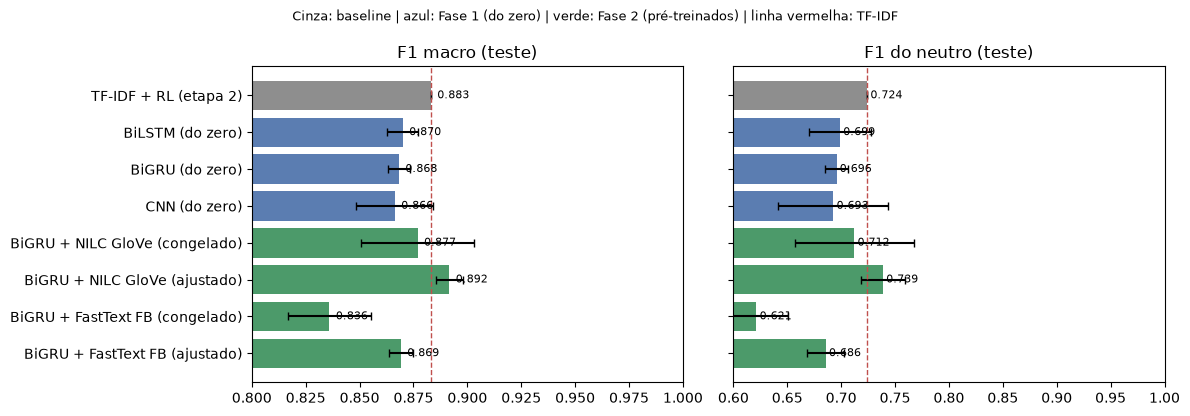

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
nomes = list(tab_num.index); ypos = np.arange(len(nomes))
for ax, met, tit in [(axs[0], "f1_macro", "F1 macro (teste)"), (axs[1], "f1_neutro", "F1 do neutro (teste)")]:
    dp = tab_num.get(met + "_dp", pd.Series(0, index=tab_num.index)).fillna(0)
    cor = ["#8E8E8E"] + ["#5B7DB1" if n in FASE1 else "#4C9A6A" for n in nomes[1:]]
    ax.barh(ypos, tab_num[met], xerr=dp, color=cor, capsize=3)
    ax.axvline(tab_num.loc["TF-IDF + RL (etapa 2)", met], color="#C0504D", ls="--", lw=1)
    ax.set_title(tit); ax.set_xlim(0.6 if met == "f1_neutro" else 0.8, 1.0)
    for y, v in zip(ypos, tab_num[met]): ax.text(v + .003, y, f"{v:.3f}", va="center", fontsize=8)
axs[0].set_yticks(ypos, nomes); axs[0].invert_yaxis()
fig.suptitle("Cinza: baseline | azul: Fase 1 (do zero) | verde: Fase 2 (pré-treinados) | linha vermelha: TF-IDF", fontsize=9)
plt.tight_layout(); plt.show()

### 8.2 Melhor modelo

O melhor modelo é escolhido pela **média do F1 macro na validação** entre todas as configurações. Dentro dela, ficamos com a semente de melhor F1 na validação. Esse é o modelo salvo em `models/` (pesos + vocabulário + configuração), que pode ser carregado com `src.redes.ClassificadorSentimento`.

Melhor configuração (validação): BiGRU + NILC GloVe (ajustado) | semente 42 | F1 val 0.924 | F1 macro teste 0.887


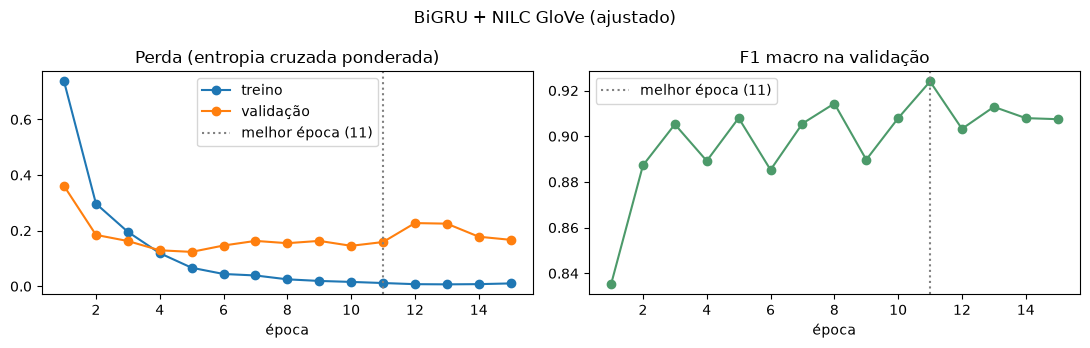

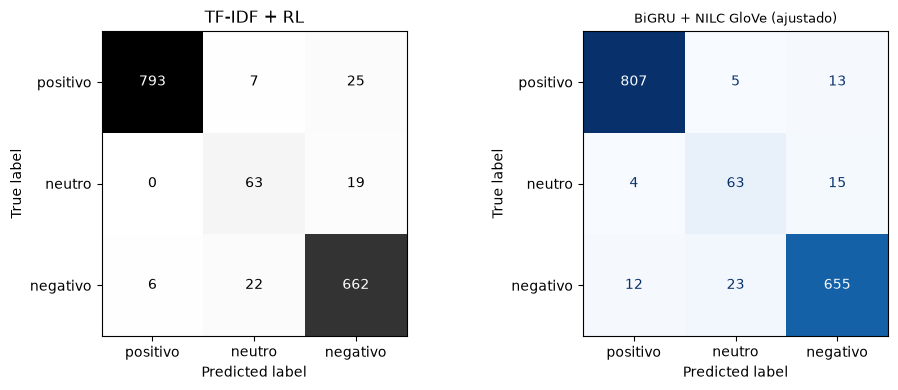

              precision    recall  f1-score   support

    positivo      0.981     0.978     0.979       825
      neutro      0.692     0.768     0.728        82
    negativo      0.959     0.949     0.954       690

    accuracy                          0.955      1597
   macro avg      0.877     0.899     0.887      1597
weighted avg      0.956     0.955     0.956      1597



In [15]:
MELHOR_NOME = tab["f1_val"].idxmax()
MELHOR_ZERO_NOME = tab.loc[list(FASE1), "f1_val"].idxmax()
mb = MELHORES[MELHOR_NOME]
print(f"Melhor configuração (validação): {MELHOR_NOME} | semente {mb['seed']} | F1 val {mb['f1_val']:.3f} | "
      f"F1 macro teste {mb['f1_macro']:.3f}")

h = mb["historico"]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
axs[0].plot(h["epoca"], h["perda_treino"], "o-", label="treino"); axs[0].plot(h["epoca"], h["perda_val"], "o-", label="validação")
axs[0].set_title("Perda (entropia cruzada ponderada)")
axs[1].plot(h["epoca"], h["f1_val"], "o-", color="#4C9A6A"); axs[1].set_title("F1 macro na validação")
for a in axs:
    a.axvline(mb["melhor_epoca"], color="gray", ls=":", label=f"melhor época ({mb['melhor_epoca']})"); a.set_xlabel("época"); a.legend()
fig.suptitle(MELHOR_NOME); plt.tight_layout(); plt.show()

pred_melhor = np.array(CLASSES)[mb["pred_teste"]]
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred_tfidf, labels=CLASSES, cmap="Greys", ax=axs[0], colorbar=False)
axs[0].set_title("TF-IDF + RL")
ConfusionMatrixDisplay.from_predictions(y_test, pred_melhor, labels=CLASSES, cmap="Blues", ax=axs[1], colorbar=False)
axs[1].set_title(MELHOR_NOME, fontsize=9)
plt.tight_layout(); plt.show()
print(classification_report(y_test, pred_melhor, labels=CLASSES, digits=3))

In [16]:
def montar_classificador(nome):
    m = MELHORES[nome]
    modelo = criar_modelo(m["arquitetura"], len(m["vocab"]), len(CLASSES))
    modelo.load_state_dict(m["estado"]); return modelo.to(DEVICE).eval(), m["vocab"]

modelo_melhor, vocab_melhor = montar_classificador(MELHOR_NOME)
config = {"arquitetura": MELHORES[MELHOR_NOME]["arquitetura"], "max_len": MAX_LEN, "configuracao": MELHOR_NOME,
          "seed": int(mb["seed"]), "f1_val": float(mb["f1_val"]), "f1_macro_teste": float(mb["f1_macro"])}
CAMINHO_MODELO = PASTA_MODELS / "sentimento_rede_neural.pt"
salvar_modelo(CAMINHO_MODELO, modelo_melhor, vocab_melhor, config, CLASSES)
print(f"Salvo em {CAMINHO_MODELO} ({CAMINHO_MODELO.stat().st_size / 1e6:.1f} MB)")

# Confere que o modelo salvo carrega e dá as mesmas previsões
clf_salvo = ClassificadorSentimento(CAMINHO_MODELO)
assert (clf_salvo.prever(list(X_test[:200])) == pred_melhor[:200]).all()
print(clf_salvo.prever(["Produto excelente, recomendo!", "Alguém sabe se vem com carregador?", "Horrível, quebrou"]))

Salvo em ..\models\sentimento_rede_neural.pt (63.0 MB)


['positivo' 'neutro' 'negativo']

## 9. Frases no estilo YouTube e erros conhecidos do TF-IDF

São as **mesmas 10 frases da etapa 2**, mais casos que o TF-IDF errou ou que testam **negação, ressalva e ironia**, onde ler a ordem das palavras deveria ajudar. Comparamos o TF-IDF, o melhor modelo do zero e o melhor modelo no geral. São poucas frases escritas por nós, então servem como **diagnóstico, não como métrica**.

In [17]:
frases = pd.DataFrame([
    # --- as 10 frases da etapa 2 ---
    ("Produto excelente, chegou rápido e funciona perfeitamente", "positivo", "etapa 2"),
    ("Meu filho amou o brinquedo, super recomendo!", "positivo", "etapa 2"),
    ("Péssimo, quebrou no segundo dia de uso", "negativo", "etapa 2"),
    ("Não recomendo, a qualidade é horrível e o suporte não responde", "negativo", "etapa 2"),
    ("Recebi o produto hoje", "neutro", "etapa 2"),
    ("Alguém sabe se esse modelo tem a versão azul?", "neutro", "etapa 2"),
    ("Mano esse carrinho é top demais 🔥🔥", "positivo", "etapa 2 — gíria"),
    ("kkkkk comprei e veio faltando peça, tô passado", "negativo", "etapa 2"),
    ("Nossa, que qualidade incrível... durou uma semana 🙄", "negativo", "etapa 2 — ironia"),
    ("Primeira vez que vejo esse canal, qual é o nome da música?", "neutro", "etapa 2"),
    # --- erros conhecidos do TF-IDF e variações ---
    ("ótimo desempenho. já é o meu segundo zenfone, não tem igual entre os intermediários.", "positivo", "negação (erro do teste)"),
    ("Não tem igual, melhor celular que já tive", "positivo", "negação"),
    ("Não é ruim não, gostei bastante", "positivo", "negação dupla"),
    ("Não gostei, não funciona direito", "negativo", "negação"),
    ("Achei que ia ser ruim, mas me surpreendeu muito", "positivo", "ressalva"),
    ("Bonito, porém parou de funcionar em um mês", "negativo", "ressalva"),
    ("Parabéns pela qualidade, quebrou na primeira semana 👏👏", "negativo", "ironia"),
    ("Esse fone é brabo demais, recomendo muito", "positivo", "gíria"),
], columns=["frase", "esperado", "tipo"])

modelo_zero, vocab_zero_m = montar_classificador(MELHOR_ZERO_NOME)
def prever_rede(modelo, vocab, textos):
    X, L = codificar_textos([limpar(t) for t in textos], vocab, MAX_LEN)
    p = torch.softmax(prever_ids(modelo, X, L), 1).numpy()
    return np.array(CLASSES)[p.argmax(1)], p.max(1)

limpas = frases["frase"].apply(limpar)
frases["TF-IDF"] = tfidf_rl.predict(limpas)
frases["do zero"], _ = prever_rede(modelo_zero, vocab_zero_m, frases["frase"])
frases["melhor"], conf = prever_rede(modelo_melhor, vocab_melhor, frases["frase"])
frases["conf. melhor"] = conf.round(2)
marca = lambda col: np.where(frases[col] == frases["esperado"], "✅ ", "❌ ") + frases[col]
vis = frases[["frase", "tipo", "esperado"]].copy()
for c in ["TF-IDF", "do zero", "melhor"]: vis[c] = marca(c)
vis["conf. melhor"] = frases["conf. melhor"]
print(f"do zero = {MELHOR_ZERO_NOME} | melhor = {MELHOR_NOME}")
print("Acertos:", {c: int((frases[c] == frases["esperado"]).sum()) for c in ["TF-IDF", "do zero", "melhor"]},
      f"de {len(frases)} | só as 10 da etapa 2:",
      {c: int((frases[c] == frases["esperado"])[:10].sum()) for c in ["TF-IDF", "do zero", "melhor"]})
vis

do zero = BiGRU (do zero) | melhor = BiGRU + NILC GloVe (ajustado)
Acertos: {'TF-IDF': 12, 'do zero': 11, 'melhor': 13} de 18 | só as 10 da etapa 2: {'TF-IDF': 8, 'do zero': 7, 'melhor': 9}


,frase,tipo,esperado,TF-IDF,do zero,melhor,conf. melhor
0,"Produto excelente, chegou rápido e funciona perfeitamente",etapa 2,positivo,✅ positivo,✅ positivo,✅ positivo,1.00
1,"Meu filho amou o brinquedo, super recomendo!",etapa 2,positivo,✅ positivo,✅ positivo,✅ positivo,1.00
2,"Péssimo, quebrou no segundo dia de uso",etapa 2,negativo,✅ negativo,✅ negativo,✅ negativo,1.00
3,"Não recomendo, a qualidade é horrível e o suporte não responde",etapa 2,negativo,✅ negativo,✅ negativo,✅ negativo,1.00
4,Recebi o produto hoje,etapa 2,neutro,✅ neutro,❌ negativo,✅ neutro,0.77
5,Alguém sabe se esse modelo tem a versão azul?,etapa 2,neutro,✅ neutro,✅ neutro,✅ neutro,1.00
6,Mano esse carrinho é top demais 🔥🔥,etapa 2 — gíria,positivo,❌ neutro,❌ neutro,✅ positivo,0.90
7,"kkkkk comprei e veio faltando peça, tô passado",etapa 2,negativo,✅ negativo,✅ negativo,✅ negativo,1.00
8,"Nossa, que qualidade incrível... durou uma semana 🙄",etapa 2 — ironia,negativo,❌ positivo,❌ positivo,❌ positivo,1.00
9,"Primeira vez que vejo esse canal, qual é o nome da música?",etapa 2,neutro,✅ neutro,✅ neutro,✅ neutro,0.99


## 10. Avaliações mistas e análise de erros

### 10.1 Mistos (fora do treino)

Como cada modelo classifica as 2.018 avaliações que elogiam e criticam ao mesmo tempo? Na etapa 2, o TF-IDF dividiu os mistos em 54% negativo, 45% positivo e quase nenhum neutro.

In [18]:
dist = {"TF-IDF + RL": pd.Series(tfidf_rl.predict(mistos["texto"])).value_counts(normalize=True)}
for nome, (m, v) in {MELHOR_ZERO_NOME: (modelo_zero, vocab_zero_m), MELHOR_NOME: (modelo_melhor, vocab_melhor)}.items():
    dist[nome] = pd.Series(prever_rede(m, v, mistos["texto"])[0]).value_counts(normalize=True)
dist = pd.DataFrame(dist).reindex(CLASSES).fillna(0)
display(dist.style.format("{:.1%}"))
_, conf_m = prever_rede(modelo_melhor, vocab_melhor, mistos["texto"])
_, conf_t = prever_rede(modelo_melhor, vocab_melhor, X_test)
print(f"Confiança média do melhor modelo: mistos {conf_m.mean():.2f} × teste (classes puras) {conf_t.mean():.2f}")

,TF-IDF + RL,BiGRU (do zero),BiGRU + NILC GloVe (ajustado)
positivo,45.5%,62.2%,60.7%
neutro,0.6%,0.9%,0.8%
negativo,53.9%,36.8%,38.5%


Confiança média do melhor modelo: mistos 0.96 × teste (classes puras) 0.98


### 10.2 Onde a rede acerta e o TF-IDF erra (e vice-versa)

Comparamos, avaliação por avaliação do teste, o TF-IDF e o melhor modelo. Também medimos o desempenho em subconjuntos com **negação** ("não", "nem", "nunca") e **ressalva** ("mas", "porém", "entretanto"), que é onde a ordem das palavras deveria fazer diferença.

In [19]:
comp = pd.DataFrame({"texto": X_test.values, "real": y_test.values, "tfidf": pred_tfidf, "rede": pred_melhor})
comp["tfidf_ok"], comp["rede_ok"] = comp["tfidf"] == comp["real"], comp["rede"] == comp["real"]
print(pd.crosstab(comp["tfidf_ok"].map({True: "TF-IDF acerta", False: "TF-IDF erra"}),
                  comp["rede_ok"].map({True: "rede acerta", False: "rede erra"})).to_string(), "\n")

print("Erros do melhor modelo por tipo (real → previsto):")
print(comp[~comp["rede_ok"]].groupby(["real", "rede"]).size().sort_values(ascending=False).to_string(), "\n")

tem = lambda pal: comp["texto"].str.contains(r"\b(?:" + "|".join(pal) + r")\b", regex=True)
subs = {"todo o teste": comp["texto"].notna(),
        "com negação (não/nem/nunca)": tem(["não", "nao", "nem", "nunca"]),
        "com ressalva (mas/porém/entretanto)": tem(["mas", "porém", "porem", "entretanto", "contudo"]),
        "sem negação nem ressalva": ~tem(["não", "nao", "nem", "nunca", "mas", "porém", "porem", "entretanto", "contudo"])}
pd.DataFrame([{"subconjunto": s, "n": int(m.sum()),
               "F1 macro TF-IDF": f1_score(comp.loc[m, "real"], comp.loc[m, "tfidf"], average="macro"),
               "F1 macro rede": f1_score(comp.loc[m, "real"], comp.loc[m, "rede"], average="macro"),
               "acurácia TF-IDF": comp.loc[m, "tfidf_ok"].mean(), "acurácia rede": comp.loc[m, "rede_ok"].mean()}
              for s, m in subs.items()]).set_index("subconjunto").round(3)

rede_ok        rede acerta  rede erra
tfidf_ok                             
TF-IDF acerta         1483         35
TF-IDF erra             42         37 

Erros do melhor modelo por tipo (real → previsto):
real      rede    
negativo  neutro      23
neutro    negativo    15
positivo  negativo    13
negativo  positivo    12
positivo  neutro       5
neutro    positivo     4 



,n,F1 macro TF-IDF,F1 macro rede,acurácia TF-IDF,acurácia rede
subconjunto,,,,,
todo o teste,1597,0.883,0.887,0.951,0.955
com negação (não/nem/nunca),645,0.827,0.844,0.932,0.935
com ressalva (mas/porém/entretanto),187,0.756,0.769,0.920,0.925
sem negação nem ressalva,900,0.909,0.911,0.967,0.971


In [20]:
print("A rede ACERTA e o TF-IDF ERRA:")
display(comp[comp["rede_ok"] & ~comp["tfidf_ok"]].sample(frac=1, random_state=SEED).head(8)[["texto", "real", "tfidf", "rede"]])
print("A rede ERRA e o TF-IDF ACERTA:")
display(comp[~comp["rede_ok"] & comp["tfidf_ok"]].sample(frac=1, random_state=SEED).head(8)[["texto", "real", "tfidf", "rede"]])

A rede ACERTA e o TF-IDF ERRA:


,texto,real,tfidf,rede
806,"não chegou. o produto ainda não chegou, qual a previsão da entrega?",neutro,negativo,neutro
302,numeraçao de bermuda pequena. numeraçao de bermuda pequena numeraçao de bermuda pequena numeraçao de bermuda pequena numeraçao de bermuda pequena,negativo,neutro,negativo
221,eu nao recebi o produto. eu nao recebi o produto eu nao recebi o produto eu nao recebi o produto,neutro,negativo,neutro
811,celular esquentando. celular esquenta a bateria e descarrega muito rápido.,negativo,positivo,negativo
119,melhorada a versão. melhor que o mais antigo que eu possuía. achei menos dolorido a retirada dos pelos,positivo,negativo,positivo
1413,não tem como avaliar. como posso avaliar um produto que não foi entregue?,neutro,negativo,neutro
524,sem produto pra avaliar. gente hoje faz exatamente dias e ainda não recebi o produto então não tenho como avaliar decepcionada é pouco pra dizer como me sin...,negativo,neutro,negativo
986,"forno elétrico ok. gostamos do forno, correspondente às nossas expectativas",positivo,neutro,positivo


A rede ERRA e o TF-IDF ACERTA:


,texto,real,tfidf,rede
1271,"não recebi ainda. não tenho como avaliar, ainda não recebi o produto! só recebi o código dos correios pela americanas.com",neutro,neutro,negativo
679,desnecessario. melhor fazer a solda do que usar essa emenda que fica falhando,negativo,negativo,positivo
1180,não recebi ainda. como vou avaliar se meu produto ainda não chegou em minha casa???,negativo,negativo,neutro
1092,................................................... não gostei.................................................................................................,negativo,negativo,neutro
779,"enganação. promete carga rápida, mas não faz o básico que é carregar.",negativo,negativo,positivo
1315,devo adivinhar???. fica meio dificil de avaliar um produto que eu não recebi...,negativo,negativo,neutro
1023,processamento de dados muito fraco. eu tenho uma samsung pol modelo série e por achá-la excelente resolvi comprar este modelo un j . eu uso muito para conec...,negativo,negativo,positivo
658,"só pode ser pegadinha..... tem certeza que o preço está certo?????? americanas, ""queimou o filme"" com isso aí, hein....... que idiota!",negativo,negativo,neutro


In [21]:
print("Os dois erram:")
comp[~comp["rede_ok"] & ~comp["tfidf_ok"]].sample(frac=1, random_state=SEED).head(8)[["texto", "real", "tfidf", "rede"]]

Os dois erram:


,texto,real,tfidf,rede
812,"meu produto não chegou. meu produto que era o celular moto g s, ainda não chegou na minha residencia",neutro,negativo,negativo
414,como fazer para verificar a arritmia?. bom dia! comprei dois aparelhos desses. um para uso pessoal e outro para um amigo! somente não consegui identificar c...,neutro,negativo,negativo
194,"perda de peso. com uma semana já da pra notar a eficácia do produto! regula bem o intestino, aliás, até demais kkk pra quem quer perder peso esse é o produto",positivo,negativo,negativo
1260,"não recebi nada até agora.. não recebi essa mercadoria até o momento, por isso não posso avaliar.",neutro,negativo,negativo
1582,"kkkkkkk. gostaria de saber se é feito de ouro? vc pega na america melhor por $ , .",negativo,neutro,neutro
1152,"prazo curto. ainda nãoposso avaliar o produto,poque faz dias que estou utilizando.",neutro,negativo,positivo
278,"do adolescente ao idoso.. desde que a pessoa saiba ler, pode aprender (e se divertir) com esse livro, não sendo necessário ser estudante das ciências da saú...",positivo,negativo,negativo
1205,desenho e acabamento. desenho e acabamento impecáveis. não espere uma simples torneira,positivo,negativo,negativo


## 11. Pontos fortes, limitações e conclusão

### Resultados principais (teste, 1.597 avaliações, média ± desvio padrão de 3 sementes)

| Configuração | Acurácia | F1 macro | F1 neutro | Parâm. treináveis | Treino | Inferência |
|---|---|---|---|---|---|---|
| TF-IDF + RL (etapa 2) | 0,951 | 0,883 | 0,724 | 53 mil | 0,4 s | 0,4 ms |
| BiLSTM (do zero) | 0,943 ± 0,002 | 0,870 ± 0,007 | 0,699 ± 0,028 | 1,9 mi | 157 s | 1,8 ms |
| BiGRU (do zero) | 0,942 ± 0,004 | 0,868 ± 0,005 | 0,696 ± 0,010 | 1,7 mi | 136 s | 3,2 ms |
| CNN (do zero) | 0,941 ± 0,004 | 0,866 ± 0,018 | 0,693 ± 0,051 | 1,8 mi | 70 s | 2,1 ms |
| BiGRU + NILC GloVe (congelado) | 0,946 ± 0,015 | 0,877 ± 0,026 | 0,712 ± 0,055 | 0,33 mi | 176 s | 3,5 ms |
| **BiGRU + NILC GloVe (ajustado)** | **0,957 ± 0,002** | **0,892 ± 0,006** | **0,739 ± 0,020** | 15,5 mi | 259 s | ~3,5 ms\* |
| BiGRU + FastText FB (congelado) | 0,927 ± 0,017 | 0,836 ± 0,019 | 0,621 ± 0,030 | 0,33 mi | 176 s | 3,6 ms |
| BiGRU + FastText FB (ajustado) | 0,946 ± 0,005 | 0,869 ± 0,005 | 0,686 ± 0,017 | 12,3 mi | 124 s | 3,5 ms |

\* A tabela da seção 8 mostra 8,9 ± 9,2 ms para essa linha porque uma das três medições foi feita com a máquina ocupada. O cálculo de inferência é o mesmo da versão congelada (mesma arquitetura e mesmo tamanho de vocabulário, ~3,5 ms); só o treino é diferente.

**Número de épocas:** o early stopping parou entre a época 6 e a 20 (melhor época entre 2 e 15), dependendo da semente. Ou seja, não houve corte prematuro sistemático. As curvas (seções 6 e 8.2) mostram que a perda de treino vai quase a zero, porque a rede memoriza o treino. Já a perda de validação chega ao mínimo por volta da época 4 ou 5 e depois sobe devagar. O F1 macro da validação continua subindo até a época 10 ou 11, mas oscila ±0,02 de uma época para outra, porque há só 49 neutros na validação. Por isso, a época escolhida tem algum ruído. Há sobreajuste, mas o early stopping pelo F1 o mantém sob controle.

### (a) Quanto vale ler a ordem das palavras? Sozinho, nada; a rede do zero **perde** para o TF-IDF

As três arquiteturas com embeddings aprendidos do zero ficaram **abaixo do baseline** em todas as métricas: F1 macro entre 0,866 e 0,870, contra 0,883 do TF-IDF, e F1 do neutro entre 0,69 e 0,70, contra 0,72. As três ficaram praticamente empatadas. Na validação, BiGRU e BiLSTM tiveram a mesma média (0,907), e a BiGRU só venceu na quarta casa decimal; a escolha entre as duas é, na prática, indiferente, e a BiGRU treina um pouco mais rápido. A CNN foi a mais rápida (metade do tempo), mas a mais instável no neutro.

Motivo provável: com ~5.400 exemplos de treino, a rede precisa aprender **ao mesmo tempo** o significado de cada palavra (1,4 milhão de parâmetros só no embedding) e como combiná-las. O TF-IDF com bigramas já captura boa parte dos padrões de ordem curta ("não recomendo", "não gostei") com muito menos parâmetros. Com esse volume de dados, a vantagem teórica de ler a sequência não compensa a falta de exemplos.

### (b) Quanto vale o conhecimento prévio? É ele que leva a rede a passar o baseline, desde que o embedding seja ajustado e o corpus combine com o domínio

- O **NILC GloVe ajustado** foi a única configuração que **superou o TF-IDF**: F1 macro de 0,892 ± 0,006 (as 3 sementes ficaram entre 0,887 e 0,899, todas acima de 0,883), acurácia de 0,957 e F1 do neutro de 0,739. Em relação à mesma BiGRU do zero, o ganho foi de +0,024 no F1 macro e +0,043 no neutro. Foi o maior efeito medido nesta etapa.
- **Congelar foi pior do que ajustar** nos dois embeddings e muito mais instável. Com o GloVe congelado, uma semente parou de melhorar na época 2 (F1 de 0,847) e as outras duas chegaram a ~0,89. Isso confirma o argumento da seção 7: em GloVe e FastText, "bom" e "ruim" ficam próximos, então os vetores precisam ser ajustados para separar as polaridades.
- O **FastText do Facebook foi pior do que o GloVe do NILC**, e a versão congelada foi o pior modelo de todos. A hipótese de que texto da web ajudaria não se confirmou *no RePro*. O corpus do NILC, mais curado e com PT-BR, combina melhor com avaliações de loja escritas em português razoavelmente padrão. A cobertura não explica a diferença (99,7% × 98,4%). Isso **pode mudar no YouTube**, onde a linguagem é mais informal, e deve ser medido com a amostra real.

### O ganho é real?

É **pequeno, mas consistente**: +0,009 no F1 macro, +0,006 na acurácia e +0,015 no F1 do neutro. As 3 sementes ficaram acima do baseline, e o modelo foi escolhido pela validação, não pelo teste. Mas o teste tem só **82 neutros**: 0,015 no F1 do neutro equivale a 1 ou 2 avaliações. **Não dá para afirmar uma superioridade forte.** A conclusão honesta é que a BiGRU com GloVe ajustado **empata com o TF-IDF ou o supera por pouco**.

Na comparação avaliação por avaliação (seção 10.2), a rede acerta 42 casos que o TF-IDF erra e erra 35 que o TF-IDF acerta. Ela ganha um pouco nos subconjuntos com **negação** (F1 de 0,844 × 0,827) e com **ressalva** (0,769 × 0,756), justamente onde a ordem das palavras deveria ajudar. As vitórias típicas são casos como "o produto ainda não chegou, qual a previsão?" (neutro), em que o TF-IDF vê "não chegou" e responde negativo.

### Pontos fortes

- **Conhecimento prévio barato:** os embeddings do NILC trazem vetores para 50 mil palavras, e a taxa de `<unk>` no teste cai de 5,2% para 2,0%. Gírias como "top", "mano" e "kkk" têm vetor. "Mano esse carrinho é top demais 🔥🔥", que o TF-IDF e a rede do zero classificaram como neutro, passou a sair como **positivo**.
- **Negação de longo alcance:** "já é o meu segundo zenfone, **não tem igual** entre os intermediários", um erro conhecido do TF-IDF, foi corrigido pelas duas redes.
- **Protocolo justo:** mesmo teste da etapa 2, validação separada, 3 sementes, escolha pela validação e os mesmos pesos de classe.
- **Latência adequada para o app:** ~3,5 ms por comentário na CPU (cerca de 300 comentários por segundo).

### Limitações

- **Ironia continua sem solução:** "Nossa, que qualidade incrível... durou uma semana 🙄" e "Parabéns pela qualidade, quebrou na primeira semana 👏👏" saem como **positivos com confiança de ~1,0**. As redes erram até o segundo caso, que o TF-IDF acertou por causa de "quebrou".
- **Negação seguida de elogio curto** ("Não tem igual, melhor celular que já tive", "Não é ruim não, gostei bastante") e **"achei que ia ser ruim, mas..."** continuam saindo como negativos nos três modelos. O "não" e o "ruim" ainda pesam mais que a estrutura da frase.
- **Emojis não têm vetor:** eles não aparecem no recorte usado (RePro + 50 mil palavras mais frequentes), e o RePro quase não tem emojis. Por isso a rede ignora 🔥, 🙄 e 👏, que são comuns no YouTube.
- **Mistos:** a rede classifica 61% dos mistos como positivos (o TF-IDF classificava 54% como negativos) e quase nunca como neutros, com **confiança média de 0,96**. Ela é confiante demais em textos ambíguos, então a confiança não serve para detectar mistos.
- **Custo:** o modelo salvo tem 63 MB (o TF-IDF ocupa menos de 1 MB), o treino leva minutos em vez de segundos e a inferência é cerca de 8 vezes mais lenta. O neutro continua sendo o ponto fraco (F1 de 0,74), principalmente na confusão entre "reclamação de entrega" e "ainda não recebi".
- **Domínio:** tudo foi medido em avaliações de loja. O desempenho em comentários do YouTube ainda é desconhecido e provavelmente menor.
- **Sem busca de hiperparâmetros:** todas as redes usaram a mesma configuração padrão. Como o early stopping não mostrou problemas (ver acima), não houve tentativas extras de regularização, para não favorecer configurações caçando resultado. Uma busca poderia melhorar um pouco as redes do zero, mas dificilmente fecharia a diferença de ~0,024 para os embeddings pré-treinados.

### Conclusão e o que isso indica para a etapa 5 e para o app

1. **A rede neural sozinha não compensa:** sem conhecimento prévio, ela perde para o TF-IDF e custa mais.
2. **O conhecimento prévio é o que importa:** a melhora veio dos embeddings pré-treinados e ajustados, não da arquitetura (BiLSTM, BiGRU e CNN empataram). Esse é o argumento para a **etapa 5**: o BERTimbau leva essa ideia ao limite, com conhecimento prévio *contextual* (o vetor de "qualidade" depende da frase inteira) e pré-treinado em muito mais texto. Ele é o candidato natural para atacar a ironia, a negação seguida de elogio e o neutro, que são os erros que sobraram aqui. O artigo do RePro reporta F1 de ~0,91 com o BERTimbau.
3. **Para o app, hoje:** a BiGRU + GloVe ajustado é a melhor opção em qualidade (F1 macro de 0,892, um ganho pequeno, mas consistente) e é rápida o suficiente. O TF-IDF, porém, continua muito competitivo: é ~8 vezes mais rápido e o arquivo é ~60 vezes menor. A escolha final fica para depois da etapa 5, comparando os três modelos em **comentários reais do YouTube rotulados pelo grupo**, onde gíria, emoji e ironia vão pesar mais.

**Arquivos gerados:** `reports/04_resultados_rede_neural.csv` (médias e desvios), `reports/04_execucoes_por_semente.csv` (cada execução) e `models/sentimento_rede_neural.pt` (BiGRU + NILC GloVe ajustado, semente 42, com vocabulário e configuração; para carregar, use `src.redes.ClassificadorSentimento`).